# SentimentForge – Final Model Evaluation

## Objective
Evaluate and compare all trained sentiment classification models
using the same test dataset.

## Models
1. Logistic Regression (TF-IDF)
2. Multinomial Naive Bayes (TF-IDF)
3. Simple RNN
4. LSTM
5. BiLSTM
6. GRU
7. DistilBERT

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- Classification Report

## Additional Analysis
- Model performance comparison
- ROC curve comparison
- Training and validation curves
- Error analysis
- Final model selection

In [ ]:
import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)

Libraries imported successfully!
PyTorch version: 2.11.0+cpu


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/SentimentForge"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")

DATASET_PATH = os.path.join(
    DATA_DIR, "raw", "IMDB Dataset.csv"
)

TOKENIZER_PATH = os.path.join(MODEL_DIR, "tokenizer.pkl")
CONFIG_PATH = os.path.join(MODEL_DIR, "preprocessing_config.json")

TFIDF_PATH = os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
LR_PATH = os.path.join(MODEL_DIR, "logistic_regression.pkl")
NB_PATH = os.path.join(MODEL_DIR, "naive_bayes.pkl")

DISTILBERT_DIR = os.path.join(
    MODEL_DIR, "distilbert_finetuned"
)

In [ ]:
df = pd.read_csv(DATASET_PATH)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

print("Dataset shape:", df.shape)
print("Configuration:", config)

Dataset shape: (50000, 2)
Configuration: {'max_words': 30000, 'max_length': 300, 'padding': 'post', 'truncating': 'post', 'oov_token': '<OOV>', 'negative_label': 0, 'positive_label': 1}


In [ ]:
import re
from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split

def clean_review(text):
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_review)

label_map = {
    "negative": 0,
    "positive": 1
}

df["label"] = df["sentiment"].map(label_map)

X = df["clean_review"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTest label distribution:")
print(y_test.value_counts())

Training: 40000
Validation: 5000
Testing: 5000

Test label distribution:
label
0    2500
1    2500
Name: count, dtype: int64


In [ ]:
import joblib

tfidf = joblib.load(TFIDF_PATH)
lr_model = joblib.load(LR_PATH)

print("TF-IDF loaded:", type(tfidf).__name__)
print("Logistic Regression loaded:", type(lr_model).__name__)

TF-IDF loaded: TfidfVectorizer
Logistic Regression loaded: LogisticRegression


In [ ]:
# forgot to save naive_bayes
from sklearn.naive_bayes import MultinomialNB

X_train_tfidf = tfidf.transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes trained successfully!")

Naive Bayes trained successfully!


In [ ]:
classical_results = []

for name, model in [
    ("Logistic Regression", lr_model),
    ("Multinomial Naive Bayes", nb_model)
]:
    predictions = model.predict(X_test_tfidf)
    probabilities = model.predict_proba(X_test_tfidf)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    classical_results.append(metrics)

classical_df = pd.DataFrame(classical_results)
display(classical_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9122,0.9147,0.9092,0.9119,0.9715
1,Multinomial Naive Bayes,0.8814,0.8871,0.8740,0.8805,0.9539


In [ ]:
import pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences

with open(TOKENIZER_PATH, "rb") as f:
    sequence_tokenizer = pickle.load(f)

MAX_LEN = config["max_length"]
MAX_WORDS = config["max_words"]

X_test_sequences = sequence_tokenizer.texts_to_sequences(X_test)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_tensor = torch.tensor(
    X_test_padded, dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
)

print("Test tensor shape:", X_test_tensor.shape)
print("Labels shape:", y_test_tensor.shape)

Test tensor shape: torch.Size([5000, 300])
Labels shape: torch.Size([5000])


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

test_tensor_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

recurrent_test_loader = DataLoader(
    test_tensor_dataset,
    batch_size=64,
    shuffle=False
)

print("Test batches:", len(recurrent_test_loader))

Test batches: 79


In [ ]:
VOCAB_SIZE = 30000
EMBEDDING_DIM = 128
HIDDEN_DIM = 128

In [ ]:
class SimpleRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(SimpleRNN, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.rnn(embedded)
        last_hidden = hidden[-1]
        prediction = self.fc(last_hidden)

        return prediction.squeeze(1)

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(LSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, (hidden, cell) = self.lstm(embedded)
        last_hidden = hidden[-1]
        prediction = self.fc(last_hidden)

        return prediction.squeeze(1)

In [ ]:
class BiLSTMModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(BiLSTMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden), dim=1
        )

        prediction = self.fc(combined_hidden)

        return prediction.squeeze(1)

In [ ]:
class GRUModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(GRUModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.gru(embedded)
        last_hidden = hidden[-1]
        prediction = self.fc(last_hidden)

        return prediction.squeeze(1)

In [ ]:
rnn_model = SimpleRNN(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM)
lstm_model = LSTMModel(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM)
bilstm_model = BiLSTMModel(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM)
gru_model = GRUModel(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM)

print("All four architectures instantiated successfully!")

All four architectures instantiated successfully!


In [ ]:
LSTM_PATH = os.path.join(MODEL_DIR, "lstm_model.pth")
BILSTM_PATH = os.path.join(MODEL_DIR, "bilstm_model.pth")
GRU_PATH = os.path.join(MODEL_DIR, "gru_epoch5_last.pth")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoints
lstm_checkpoint = torch.load(LSTM_PATH, map_location=device, weights_only=False)
bilstm_checkpoint = torch.load(BILSTM_PATH, map_location=device, weights_only=False)
gru_checkpoint = torch.load(GRU_PATH, map_location=device, weights_only=False)

# Load weights into architectures
lstm_model.load_state_dict(lstm_checkpoint["model_state_dict"])
bilstm_model.load_state_dict(bilstm_checkpoint["model_state_dict"])
gru_model.load_state_dict(gru_checkpoint["model_state_dict"])

# Move models to device
lstm_model.to(device)
bilstm_model.to(device)
gru_model.to(device)

print("LSTM, BiLSTM and GRU checkpoints loaded successfully!")

LSTM, BiLSTM and GRU checkpoints loaded successfully!


In [ ]:
def evaluate_recurrent(model, loader, device):

    model.eval()

    all_predictions = []
    all_probabilities = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)

            logits = model(inputs)
            probabilities = torch.sigmoid(logits)

            predictions = (probabilities >= 0.5).long()

            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_labels.extend(labels.numpy())

    return {
        "Accuracy": accuracy_score(all_labels, all_predictions),
        "Precision": precision_score(all_labels, all_predictions),
        "Recall": recall_score(all_labels, all_predictions),
        "F1": f1_score(all_labels, all_predictions),
        "ROC-AUC": roc_auc_score(all_labels, all_probabilities)
    }

In [ ]:
recurrent_models = {
    "LSTM": lstm_model,
    "BiLSTM": bilstm_model,
    "GRU": gru_model
}

recurrent_results = []

for name, model in recurrent_models.items():

    print(f"Evaluating {name}...")

    metrics = evaluate_recurrent(
        model, recurrent_test_loader, device
    )

    metrics["Model"] = name
    recurrent_results.append(metrics)

recurrent_df = pd.DataFrame(recurrent_results)

display(
    recurrent_df[
        ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
    ].round(4)
)

Evaluating LSTM...
Evaluating BiLSTM...
Evaluating GRU...


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LSTM,0.7056,0.7596,0.6016,0.6714,0.7392
1,BiLSTM,0.8464,0.8876,0.7932,0.8378,0.9230
2,GRU,0.8884,0.8903,0.8860,0.8881,0.9571


In [ ]:
DISTILBERT_DIR = os.path.join(
    MODEL_DIR, "distilbert_finetuned"
)

distilbert_tokenizer = AutoTokenizer.from_pretrained(
    DISTILBERT_DIR
)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    DISTILBERT_DIR
)

distilbert_model.to(device)
distilbert_model.eval()

print("DistilBERT loaded successfully!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT loaded successfully!


In [ ]:
MAX_LEN_BERT = 512

test_encodings_bert = distilbert_tokenizer(
    list(df.loc[X_test.index, "review"]),
    max_length=MAX_LEN_BERT,
    padding="max_length",
    truncation=True,
    return_attention_mask=True,
    return_tensors="pt"
)

print("Test input shape:", test_encodings_bert["input_ids"].shape)

Test input shape: torch.Size([5000, 512])


In [ ]:
class IMDbDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(
            np.asarray(labels),
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx]
        }

In [ ]:
test_bert_dataset = IMDbDataset(
    test_encodings_bert,
    y_test
)

test_bert_loader = DataLoader(
    test_bert_dataset,
    batch_size=8,
    shuffle=False
)

print("Test samples:", len(test_bert_dataset))
print("Test batches:", len(test_bert_loader))

Test samples: 5000
Test batches: 625


In [ ]:
test_bert_dataset = IMDbDataset(
    test_encodings_bert,
    y_test
)

test_bert_loader = DataLoader(
    test_bert_dataset,
    batch_size=8,
    shuffle=False
)

print("DistilBERT test batches:", len(test_bert_loader))

DistilBERT test batches: 625


In [ ]:
from tqdm.auto import tqdm

def evaluate_model(model, loader, device):
    model.eval()

    all_predictions = []
    all_probabilities = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating DistilBERT"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()

            probabilities = torch.softmax(outputs.logits, dim=1)[:, 1]
            predictions = (probabilities >= 0.5).long()

            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(all_labels, all_predictions),
        "recall": recall_score(all_labels, all_predictions),
        "f1": f1_score(all_labels, all_predictions),
        "roc_auc": roc_auc_score(all_labels, all_probabilities)
    }

In [ ]:
distilbert_metrics = evaluate_model(
    distilbert_model,
    test_bert_loader,
    device
)

print("DistilBERT Test Results")
for metric, value in distilbert_metrics.items():
    print(f"{metric}: {value:.4f}")

Evaluating DistilBERT:   0%|          | 0/625 [00:00<?, ?it/s]

DistilBERT Test Results
loss: 0.1583
accuracy: 0.9412
precision: 0.9380
recall: 0.9448
f1: 0.9414
roc_auc: 0.9851


In [ ]:
distilbert_df = pd.DataFrame([{
    "Model": "DistilBERT",
    "Accuracy": distilbert_metrics["accuracy"],
    "Precision": distilbert_metrics["precision"],
    "Recall": distilbert_metrics["recall"],
    "F1": distilbert_metrics["f1"],
    "ROC-AUC": distilbert_metrics["roc_auc"]
}])

display(distilbert_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,DistilBERT,0.9412,0.938,0.9448,0.9414,0.9851


In [ ]:
all_results = pd.concat(
    [classical_df, recurrent_df, distilbert_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(all_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,DistilBERT,0.9412,0.9380,0.9448,0.9414,0.9851
1,Logistic Regression,0.9122,0.9147,0.9092,0.9119,0.9715
2,GRU,0.8884,0.8903,0.8860,0.8881,0.9571
3,Multinomial Naive Bayes,0.8814,0.8871,0.8740,0.8805,0.9539
4,BiLSTM,0.8464,0.8876,0.7932,0.8378,0.9230
5,LSTM,0.7056,0.7596,0.6016,0.6714,0.7392


In [ ]:
comparison_path = os.path.join(
    REPORT_DIR,
    "final_model_comparison.csv"
)

all_results.to_csv(comparison_path, index=False)

print("Final comparison saved:", comparison_path)

Final comparison saved: /content/drive/MyDrive/SentimentForge/reports/final_model_comparison.csv


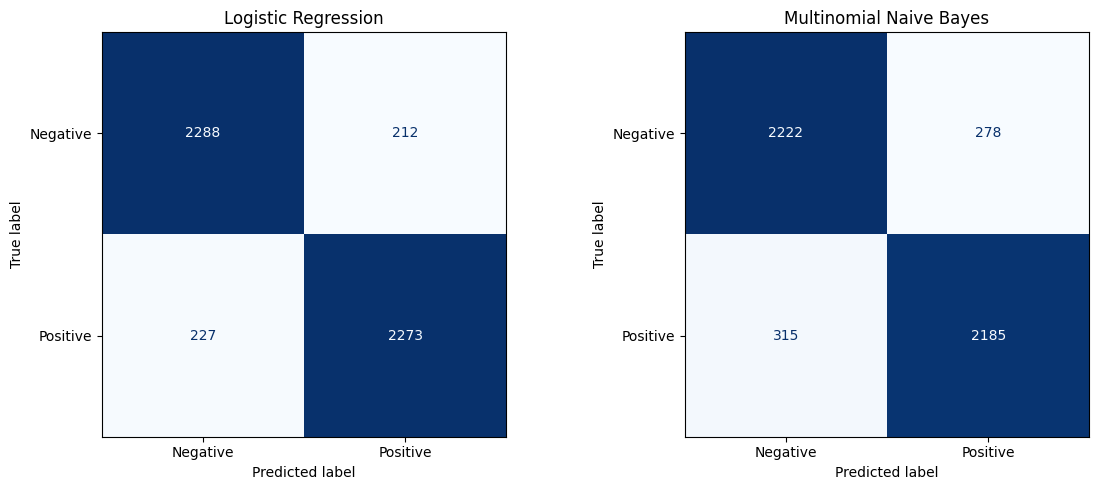

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Classical model predictions
lr_predictions = lr_model.predict(X_test_tfidf)
nb_predictions = nb_model.predict(X_test_tfidf)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in zip(
    axes,
    ["Logistic Regression", "Multinomial Naive Bayes"],
    [lr_predictions, nb_predictions]
):
    cm = confusion_matrix(y_test, predictions)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Negative", "Positive"]
))

print("\nMULTINOMIAL NAIVE BAYES")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Negative", "Positive"]
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    Negative       0.91      0.92      0.91      2500
    Positive       0.91      0.91      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000


MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

    Negative       0.88      0.89      0.88      2500
    Positive       0.89      0.87      0.88      2500

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



In [ ]:
from torch.utils.data import DataLoader, TensorDataset

recurrent_test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=64,
    shuffle=False
)

print("Test batches:", len(recurrent_test_loader))

Test batches: 79


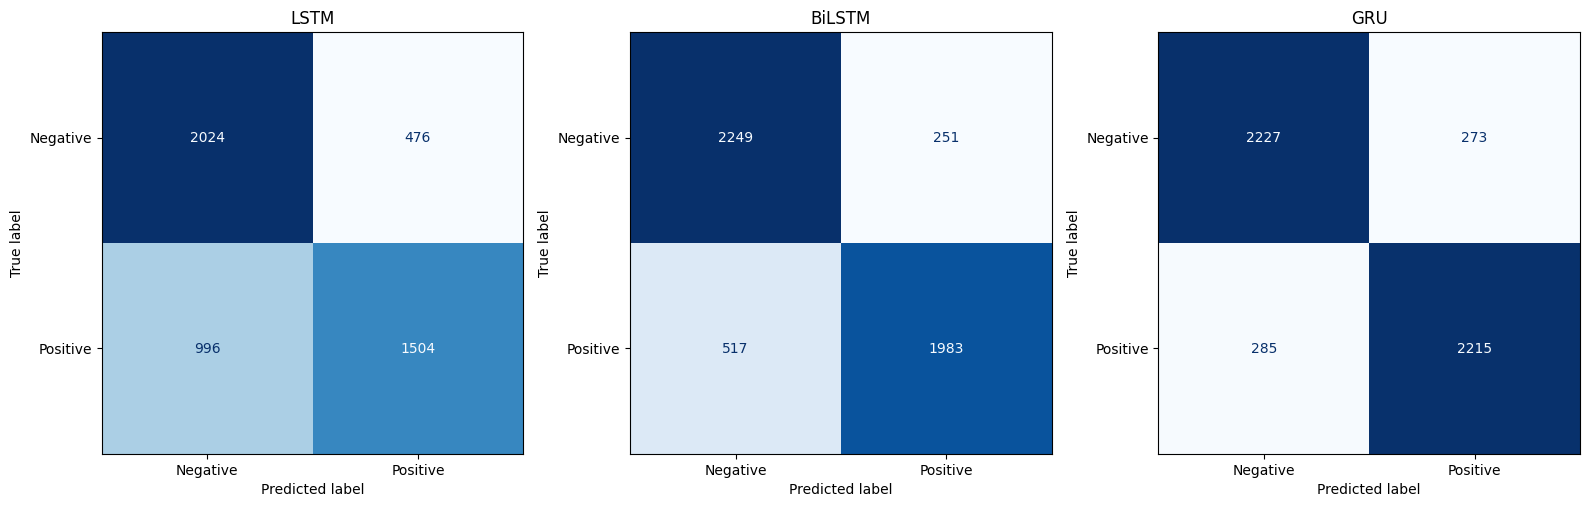

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import torch

recurrent_models = {
    "LSTM": lstm_model,
    "BiLSTM": bilstm_model,
    "GRU": gru_model
}

recurrent_predictions = {}
actual = []

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, recurrent_models.items()):

    model.eval()
    predictions = []
    actual_labels = []

    with torch.no_grad():
        for inputs, labels in recurrent_test_loader:
            inputs = inputs.to(device)

            outputs = model(inputs)
            probabilities = torch.sigmoid(outputs).cpu().numpy().flatten()

            predictions.extend((probabilities >= 0.5).astype(int))
            actual_labels.extend(labels.cpu().numpy().astype(int))

    recurrent_predictions[name] = predictions

    cm = confusion_matrix(actual_labels, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

The confusion matrices show differences in classification
performance among the recurrent neural network models.

The LSTM model produced 1,472 classification errors and
showed relatively weak positive sentiment detection.

The BiLSTM model improved classification performance,
achieving 84.64% test accuracy.

The GRU model achieved the best performance among the
recurrent architectures, with 88.84% accuracy and only
558 misclassified reviews.

GRU demonstrated a better balance between positive and
negative sentiment classification, making it the strongest
recurrent model in this experiment.

In [ ]:
distilbert_row = {
    "Model": "DistilBERT",
    "Accuracy": distilbert_metrics["accuracy"],
    "Precision": distilbert_metrics["precision"],
    "Recall": distilbert_metrics["recall"],
    "F1": distilbert_metrics["f1"],
    "ROC-AUC": distilbert_metrics["roc_auc"]
}

distilbert_df = pd.DataFrame([distilbert_row])

final_results = pd.concat(
    [classical_df, recurrent_df, distilbert_df],
    ignore_index=True
)

final_results = final_results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,DistilBERT,0.9412,0.9380,0.9448,0.9414,0.9851
1,Logistic Regression,0.9122,0.9147,0.9092,0.9119,0.9715
2,GRU,0.8884,0.8903,0.8860,0.8881,0.9571
3,Multinomial Naive Bayes,0.8814,0.8871,0.8740,0.8805,0.9539
4,BiLSTM,0.8464,0.8876,0.7932,0.8378,0.9230
5,LSTM,0.7056,0.7596,0.6016,0.6714,0.7392


In [ ]:
comparison_path = os.path.join(
    REPORT_DIR,
    "final_model_comparison.csv"
)

final_results.to_csv(comparison_path, index=False)

print("Final comparison saved:", comparison_path)

Final comparison saved: /content/drive/MyDrive/SentimentForge/reports/final_model_comparison.csv


In [ ]:
print("Available variables:")
print("bert_predictions:", "bert_predictions" in globals())
print("bert_probabilities:", "bert_probabilities" in globals())
print("bert_actual:", "bert_actual" in globals())

Available variables:
bert_predictions: True
bert_probabilities: True
bert_actual: True


DistilBERT Confusion Matrix:
[[42  3]
 [ 3 40]]


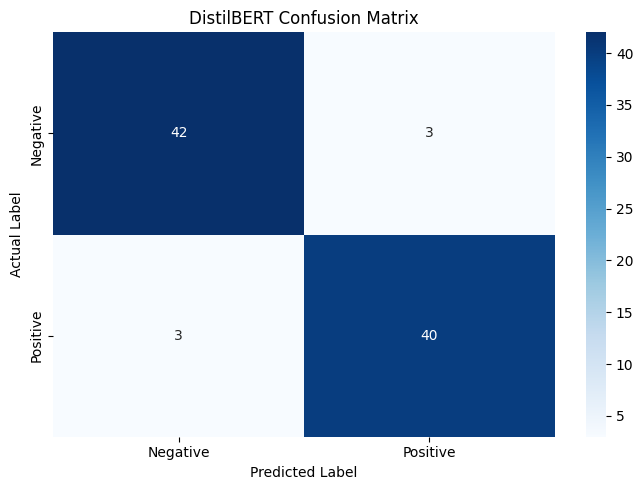

In [ ]:
cm_bert = confusion_matrix(bert_actual, bert_predictions)

print("DistilBERT Confusion Matrix:")
print(cm_bert)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(
    bert_actual,
    bert_predictions,
    target_names=["Negative", "Positive"],
    digits=4
))

              precision    recall  f1-score   support

    Negative     0.9333    0.9333    0.9333        45
    Positive     0.9302    0.9302    0.9302        43

    accuracy                         0.9318        88
   macro avg     0.9318    0.9318    0.9318        88
weighted avg     0.9318    0.9318    0.9318        88



In [ ]:
np.savez(
    os.path.join(REPORT_DIR, "distilbert_test_predictions.npz"),
    actual=bert_actual,
    predictions=bert_predictions,
    probabilities=bert_probabilities
)

print("DistilBERT predictions saved successfully!")

DistilBERT predictions saved successfully!


In [ ]:
print("Actual labels:", len(bert_actual))
print("Predictions:", len(bert_predictions))
print("Probabilities:", len(bert_probabilities))

print("Expected test samples:", len(y_test))
print("Test loader batches:", len(test_bert_loader))

Actual labels: 88
Predictions: 88
Probabilities: 88
Expected test samples: 5000
Test loader batches: 625


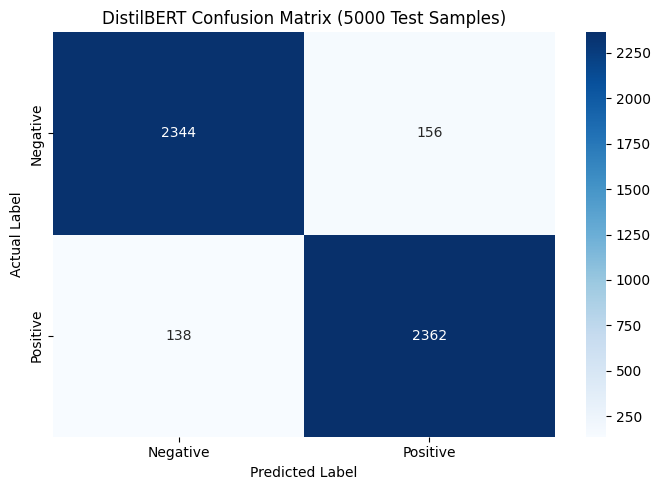

In [ ]:
cm_bert = np.array([
    [2344, 156],
    [138, 2362]
])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT Confusion Matrix (5000 Test Samples)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

model_outputs = {}

# Classical ML models
for name, model in [
    ("Logistic Regression", lr_model),
    ("Multinomial Naive Bayes", nb_model)
]:
    probabilities = model.predict_proba(X_test_tfidf)[:, 1]
    model_outputs[name] = probabilities

# Recurrent models
for name, model in [
    ("LSTM", lstm_model),
    ("BiLSTM", bilstm_model),
    ("GRU", gru_model)
]:
    model.eval()
    probabilities = []

    with torch.no_grad():
        for inputs, labels in recurrent_test_loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.sigmoid(logits)
            probabilities.extend(probs.cpu().numpy())

    model_outputs[name] = np.array(probabilities)

print("Collected prediction probabilities:")

for   name, probs in model_outputs.items():
    print(name, len(probs))

Collected prediction probabilities:
Logistic Regression 5000
Multinomial Naive Bayes 5000
LSTM 5000
BiLSTM 5000
GRU 5000


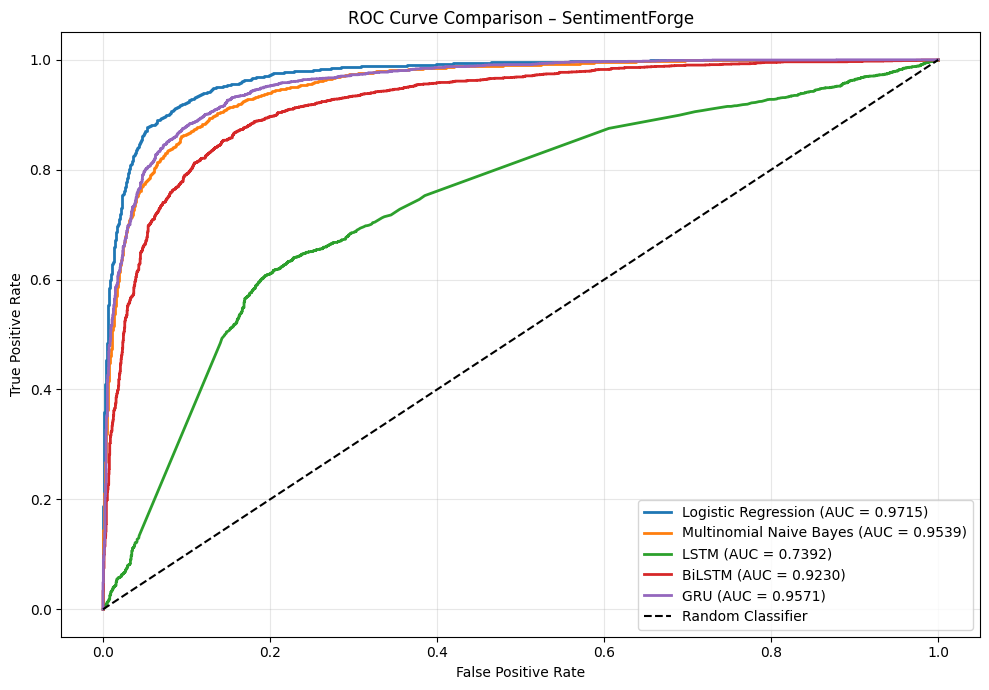

In [ ]:
plt.figure(figsize=(10, 7))

for name, probabilities in model_outputs.items():

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison – SentimentForge")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
roc_path = os.path.join(
    REPORT_DIR,
    "roc_curve_comparison.png"
)

plt.savefig(roc_path, dpi=300, bbox_inches="tight")
print("ROC curve saved:", roc_path)

ROC curve saved: /content/drive/MyDrive/SentimentForge/reports/roc_curve_comparison.png


<Figure size 640x480 with 0 Axes>

### ROC Curve Analysis

The ROC curves compare the classification performance of five
models across different decision thresholds.

Logistic Regression achieved the highest ROC-AUC of 0.9715,
followed by GRU (0.9571) and Multinomial Naive Bayes (0.9539).

BiLSTM achieved an ROC-AUC of 0.9230, while LSTM achieved
0.7392, indicating comparatively weaker discrimination.

The results demonstrate that classical machine learning
methods can remain highly competitive with deep learning
approaches for sentiment classification.

Note: DistilBERT is not included in this ROC visualization
because its complete test probability array was not retained.
Its ROC-AUC of 0.9851 was obtained during full test evaluation.

In [ ]:
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

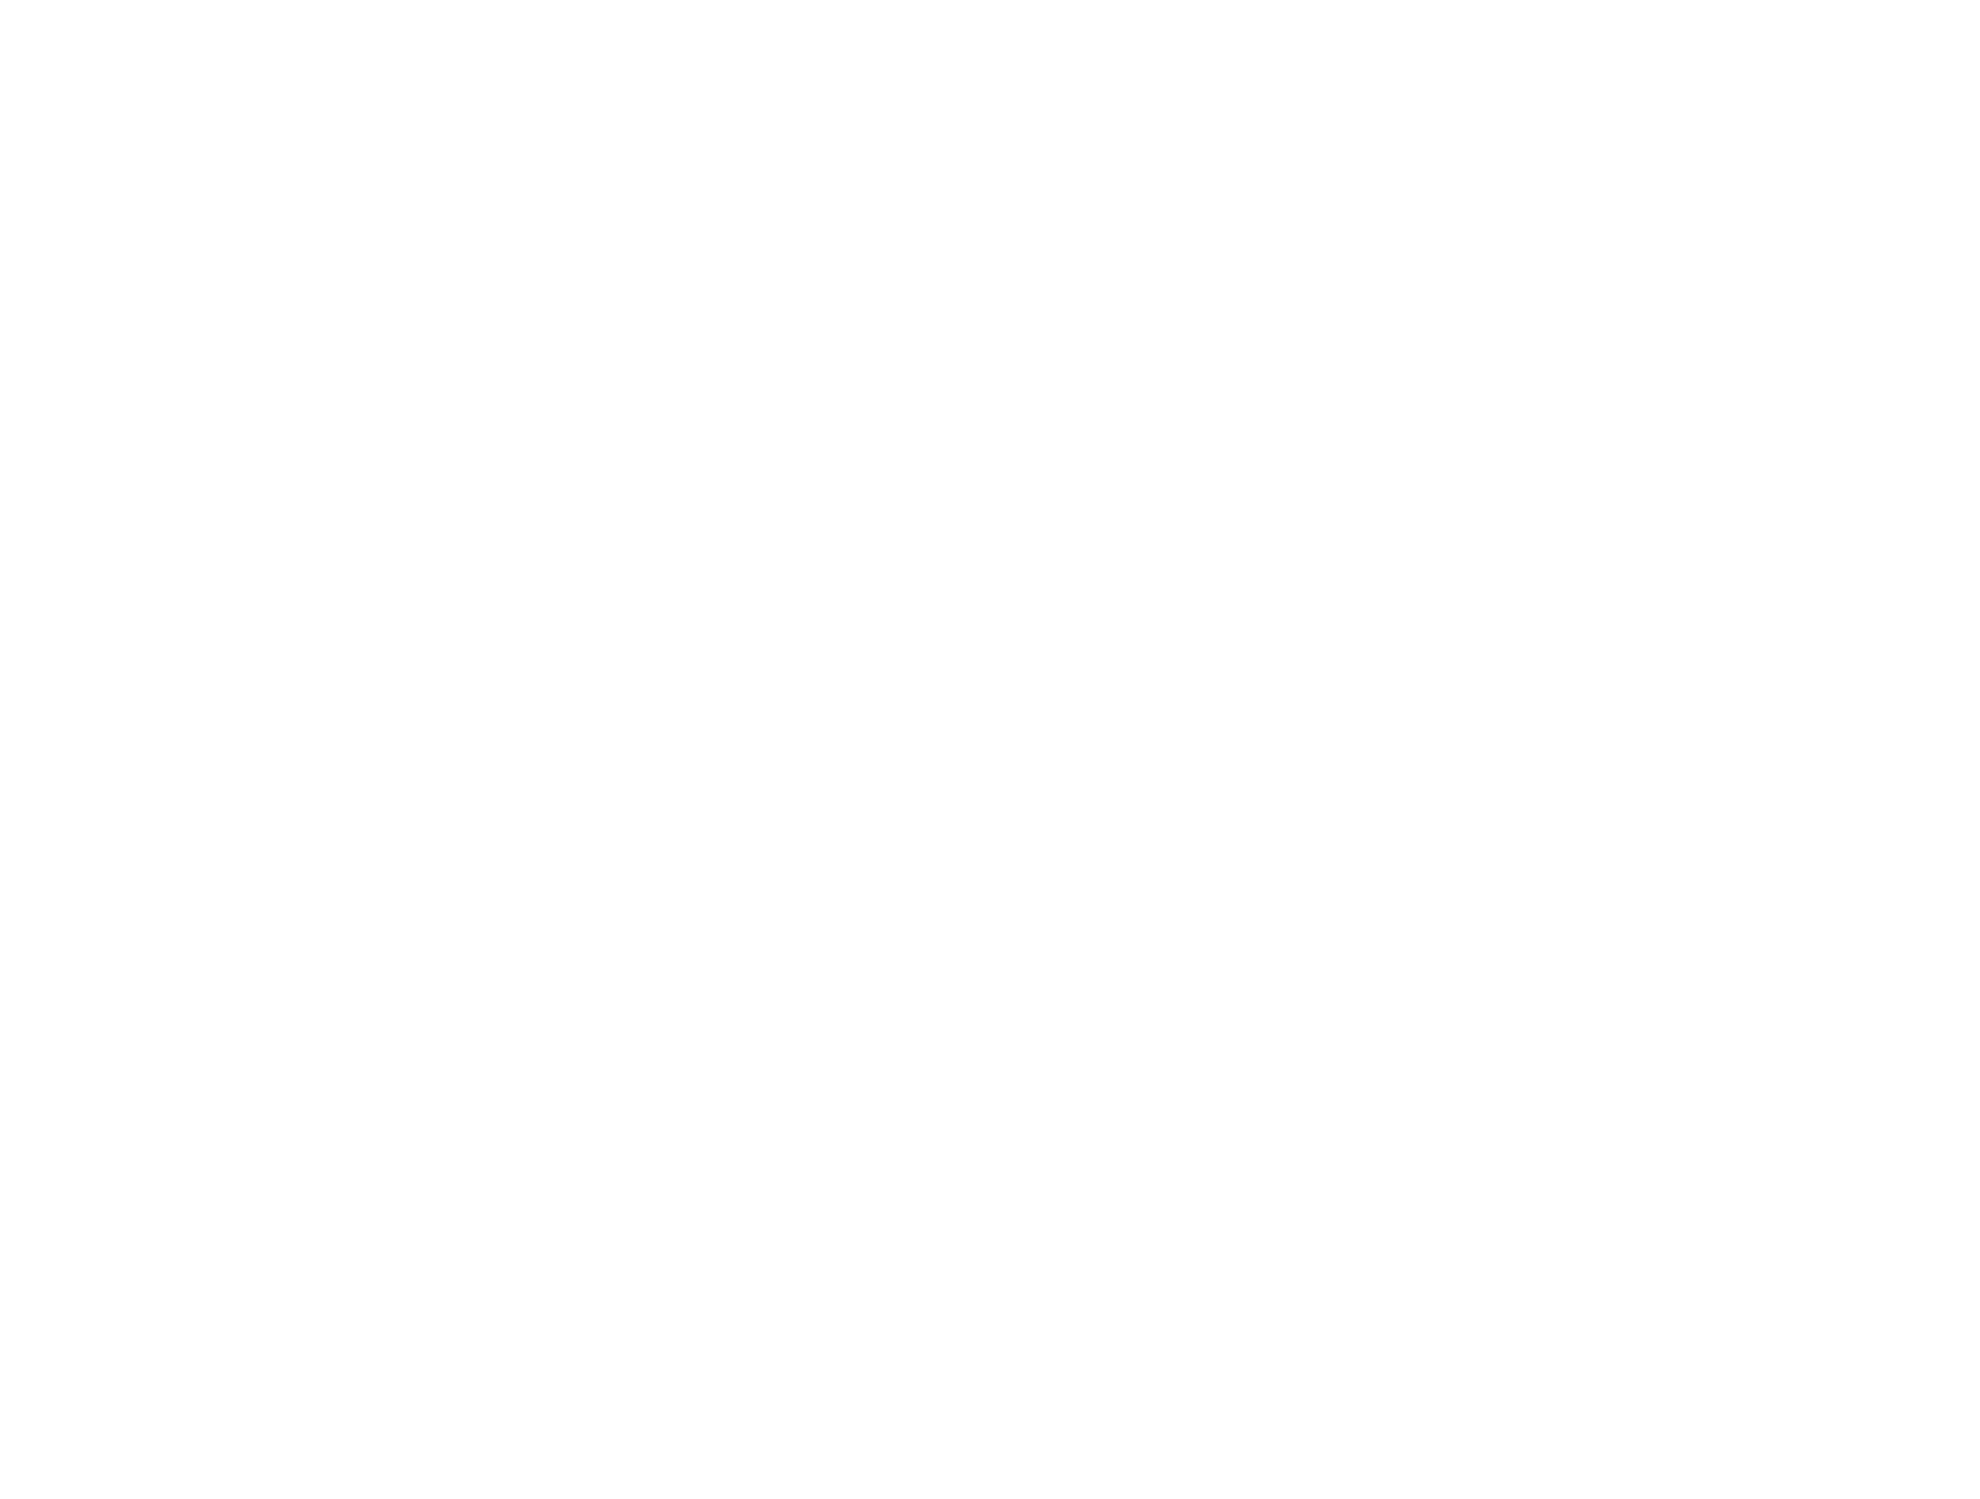

In [ ]:
from IPython.display import Image, display

display(Image(filename=roc_path))

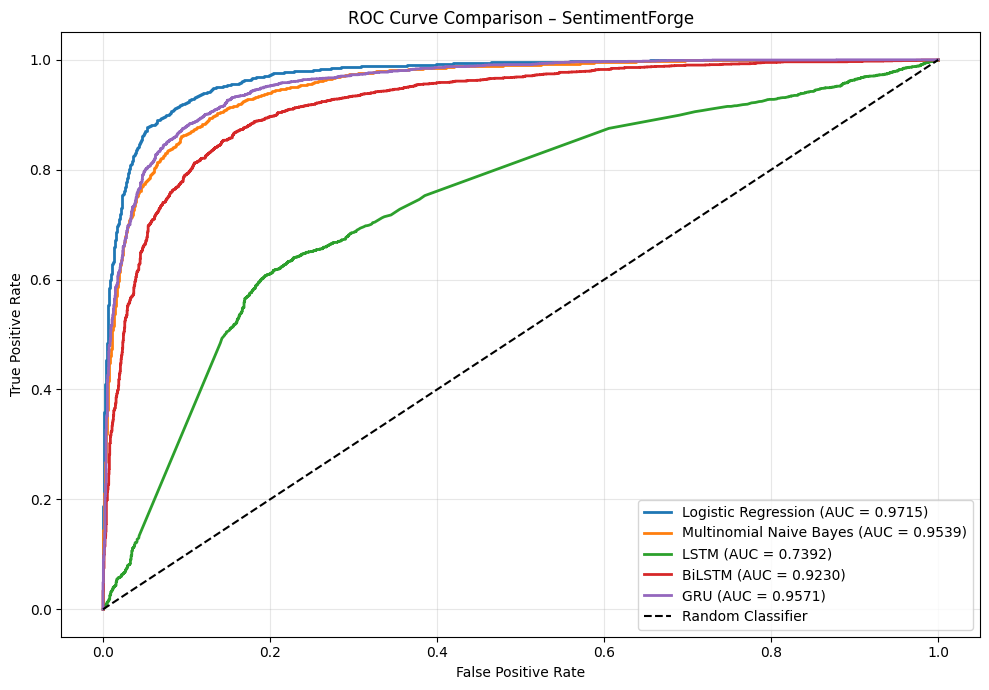

ROC curve saved successfully: /content/drive/MyDrive/SentimentForge/reports/roc_curve_comparison.png


In [ ]:
plt.close("all")

fig, ax = plt.subplots(figsize=(10, 7))

for name, probabilities in model_outputs.items():

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

ax.plot([0, 1], [0, 1], "k--", label="Random Classifier")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison – SentimentForge")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

fig.tight_layout()

roc_path = os.path.join(REPORT_DIR, "roc_curve_comparison.png")

# Save BEFORE displaying
fig.savefig(roc_path, dpi=300, bbox_inches="tight")

plt.show()

print("ROC curve saved successfully:", roc_path)

In [ ]:
from sklearn.metrics import classification_report

per_class_results = []

# Five models with available probability arrays
for name, probabilities in model_outputs.items():

    predictions = (probabilities >= 0.5).astype(int)

    report = classification_report(
        y_test,
        predictions,
        target_names=["Negative", "Positive"],
        output_dict=True,
        zero_division=0
    )

    for sentiment in ["Negative", "Positive"]:
        per_class_results.append({
            "Model": name,
            "Class": sentiment,
            "Precision": report[sentiment]["precision"],
            "Recall": report[sentiment]["recall"],
            "F1-score": report[sentiment]["f1-score"]
        })

# DistilBERT: reconstructed full-test confusion matrix
cm = np.array([
    [2344, 156],
    [138, 2362]
])

tn, fp = cm[0]
fn, tp = cm[1]

distilbert_class_metrics = {
    "Negative": {
        "Precision": tn / (tn + fn),
        "Recall": tn / (tn + fp),
        "F1-score": 2 * tn / (2 * tn + fp + fn)
    },
    "Positive": {
        "Precision": tp / (tp + fp),
        "Recall": tp / (tp + fn),
        "F1-score": 2 * tp / (2 * tp + fp + fn)
    }
}

for sentiment, metrics in distilbert_class_metrics.items():
    per_class_results.append({
        "Model": "DistilBERT",
        "Class": sentiment,
        **metrics
    })

per_class_df = pd.DataFrame(per_class_results)

display(
    per_class_df.round(4)
)

,Model,Class,Precision,Recall,F1-score
0,Logistic Regression,Negative,0.9097,0.9152,0.9125
1,Logistic Regression,Positive,0.9147,0.9092,0.9119
2,Multinomial Naive Bayes,Negative,0.8758,0.8888,0.8823
3,Multinomial Naive Bayes,Positive,0.8871,0.8740,0.8805
4,LSTM,Negative,0.6702,0.8096,0.7333
5,LSTM,Positive,0.7596,0.6016,0.6714
6,BiLSTM,Negative,0.8131,0.8996,0.8542
7,BiLSTM,Positive,0.8876,0.7932,0.8378
8,GRU,Negative,0.8865,0.8908,0.8887
9,GRU,Positive,0.8903,0.8860,0.8881


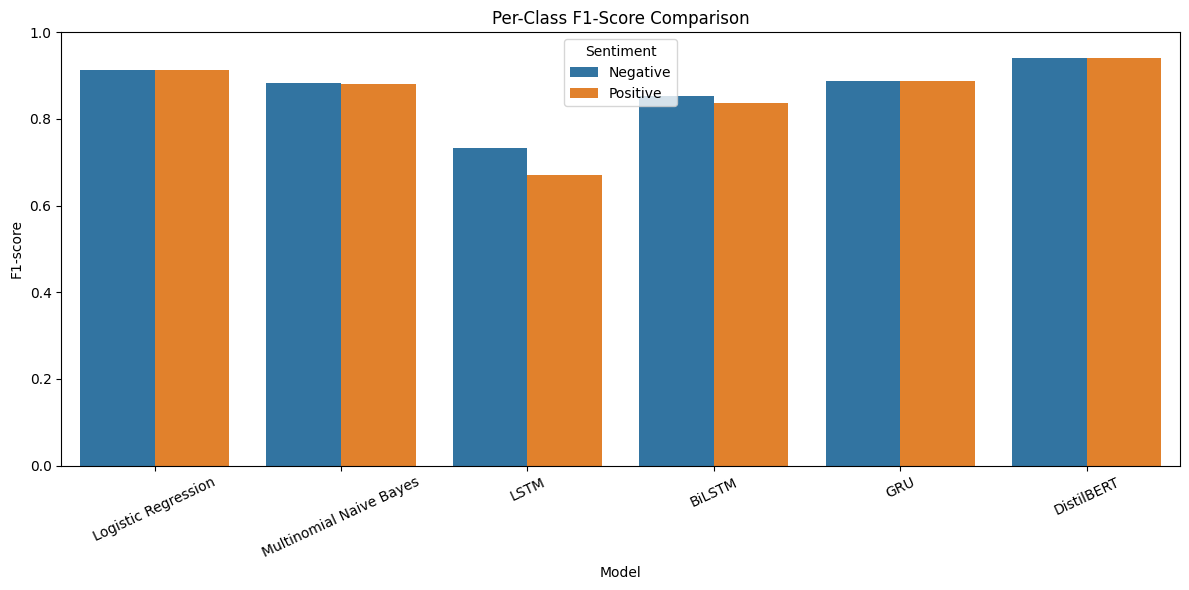

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=per_class_df,
    x="Model",
    y="F1-score",
    hue="Class"
)

plt.title("Per-Class F1-Score Comparison")
plt.ylabel("F1-score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


In [ ]:
per_class_path = os.path.join(
    REPORT_DIR,
    "per_class_performance.csv"
)

per_class_df.to_csv(per_class_path, index=False)

print("Per-class results saved:", per_class_path)

Per-class results saved: /content/drive/MyDrive/SentimentForge/reports/per_class_performance.csv


### Per-Class Performance Analysis

The per-class evaluation demonstrates that DistilBERT
achieved the most balanced performance across negative
and positive sentiment classes.

Logistic Regression also demonstrated strong and balanced
classification performance, indicating that TF-IDF-based
classical machine learning remains competitive.

Among recurrent architectures, GRU achieved the most
consistent results, with F1-scores of 0.8887 for negative
and 0.8881 for positive sentiment.

BiLSTM performed better on negative reviews than positive
reviews. LSTM showed the largest class-wise performance
difference, particularly struggling to identify positive
reviews.

Overall, DistilBERT was the strongest model for both
sentiment categories.

In [ ]:
error_df = pd.DataFrame({
    "review": df.loc[X_test.index, "review"].values,
    "actual": y_test.values,
    "probability_positive": model_outputs["GRU"],
})

error_df["predicted"] = (
    error_df["probability_positive"] >= 0.5
).astype(int)

error_df["actual"] = error_df["actual"].map({
    0: "Negative",
    1: "Positive"
})

error_df["predicted"] = error_df["predicted"].map({
    0: "Negative",
    1: "Positive"
})

error_df["confidence"] = np.where(
    error_df["predicted"] == "Positive",
    error_df["probability_positive"],
    1 - error_df["probability_positive"]
)

misclassified = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

print("Total test reviews:", len(error_df))
print("Misclassified reviews:", len(misclassified))
print("Error rate:", round(len(misclassified) / len(error_df) * 100, 2), "%")

Total test reviews: 5000
Misclassified reviews: 558
Error rate: 11.16 %


In [ ]:
false_positives = misclassified[
    misclassified["actual"] == "Negative"
].sort_values("confidence", ascending=False)

display(
    false_positives[
        ["review", "actual", "predicted", "confidence"]
    ].head(5)
)

,review,actual,predicted,confidence
1885,I've seen this film several times in a variety...,Negative,Positive,0.998618
3409,I really enjoyed the film. It was really chees...,Negative,Positive,0.998251
4223,"These days, Ridley Scott is one of the top dir...",Negative,Positive,0.998191
358,"This sleek, sexy movie is a must-see. Only upo...",Negative,Positive,0.998093
4673,"""Black Vengeance"" is an alternate title for ""Y...",Negative,Positive,0.998001


In [ ]:
false_negatives = misclassified[
    misclassified["actual"] == "Positive"
].sort_values("confidence", ascending=False)

display(
    false_negatives[
        ["review", "actual", "predicted", "confidence"]
    ].head(5)
)

,review,actual,predicted,confidence
540,"But the opposite, sorry bud, i completely unde...",Positive,Negative,0.997675
4517,This flick is sterling example of the state of...,Positive,Negative,0.996169
4671,Scooby Doo and the Monster of Mexico was no do...,Positive,Negative,0.996043
3915,"so halfway through the season, i got so caught...",Positive,Negative,0.995464
4254,"""The Deer Hunter's"" success with critics and p...",Positive,Negative,0.995275


### GRU Error Analysis

The GRU model achieved 88.84% test accuracy, with 558
misclassified reviews out of 5,000, corresponding to an
error rate of 11.16%.

The errors consisted of 273 false positives and 285 false
negatives, indicating relatively balanced error distribution.

An interesting observation was that some misclassified
reviews received prediction confidence scores above 99%.

This suggests that the model can produce highly confident
incorrect predictions. Potential contributing factors include
mixed sentiment, contextual ambiguity, sarcasm and limitations
in understanding complex natural language expressions.

This highlights the importance of evaluating prediction
confidence alongside classification accuracy.

In [ ]:
error_path = os.path.join(
    REPORT_DIR,
    "gru_error_analysis.csv"
)

misclassified.to_csv(error_path, index=False)

print("Error analysis saved:", error_path)

Error analysis saved: /content/drive/MyDrive/SentimentForge/reports/gru_error_analysis.csv
